# 05 - Numerical Feature Scaling
**Project:** Rossmann Store Sales - Data Preprocessing Notebooks

**Goal:** put numerical features on comparable scales, compare the main scalers in scikit-learn, and see *when* scaling
matters (and when it doesn't).

**Contents**
1. Why scale?
2. Load data & choose the features to scale
3. Train / test split (to avoid data leakage)
4. The problem: very different ranges
5. The scalers (Standard, MinMax, MaxAbs, Robust) + manual check
6. Visual comparison - the shape does not change
7. Effect of outliers
8. Normalizer (row-wise) - a different idea
9. Effect on models (KNN, Ridge, Random Forest)
10. Production-style `ColumnTransformer` + `inverse_transform`
11. Which scaler should I use?

## 1. Why scale?
Our numeric features live on completely different ranges: months go from 1 to 12, years are around 2,000, and
`CompetitionDistance` goes up to 75,860 meters.

| Model family | Sensitive to feature scale? | Why |
|---|---|---|
| KNN, K-Means, SVM, neural networks | **Yes** | They use distances / dot products - the biggest-range feature dominates |
| Linear / Ridge / Lasso, Logistic regression | **Yes** (regularised or gradient-based) | Penalties and gradient descent depend on coefficient size |
| PCA | **Yes** | Variance-based - large-variance features dominate |
| Decision trees, Random Forest, XGBoost, LightGBM | **No** | They split on thresholds, so monotonic rescaling changes nothing |

> **Golden rule:** fit the scaler on the **training data only**, then use it to transform train *and* test.
> Fitting on everything leaks information from the test set into training.

## 2. Load data & choose the features to scale

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, Normalizer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42

In [ ]:
DATA_PATH = "../data/train.csv"   # change this if the file is in another folder

df = pd.read_csv(DATA_PATH, dtype={"StateHoliday": "str"}, parse_dates=["Date"])

# Closed days have Sales = 0 and carry no information -> keep open days with sales only
df = df[(df["Open"] == 1) & (df["Sales"] > 0)].copy()
print(f"Rows used: {len(df):,}")

Rows used: 844,338


**Which columns do we scale?** Only *continuous numeric* features:

| Scale these | Do NOT scale these |
|---|---|
| `Customers`, `CompetitionDistance`, `CompetitionOpenSinceMonth`, `CompetitionOpenSinceYear`, `Promo2SinceWeek`, `Promo2SinceYear` | Binary flags (`Promo`, `SchoolHoliday`, `Promo2`) - already 0/1 |
| | Categorical codes such as `DayOfWeek`, `Store` (they are labels, not quantities - see notebook 07) |
| | The target `Sales` (we keep it in its original units) |

Some of these columns contain NaN (see notebook 03). Here we only use a simple **median imputer** so the scalers can run;
the proper missing-value strategy belongs to notebook 03.

In [ ]:
num_cols = ["Customers", "CompetitionDistance", "CompetitionOpenSinceMonth",
            "CompetitionOpenSinceYear", "Promo2SinceWeek", "Promo2SinceYear"]
binary_cols = ["Promo", "SchoolHoliday", "Promo2"]
target = "Sales"

display(df[num_cols].describe().T[["count", "min", "max", "mean", "std"]])

,count,min,max,mean,std
Customers,"844,338.000",8.000,"7,388.000",762.777,401.194
CompetitionDistance,"842,152.000",20.000,"75,860.000","5,458.157","7,809.573"
CompetitionOpenSinceMonth,"575,738.000",1.000,12.000,7.225,3.210
CompetitionOpenSinceYear,"575,738.000","1,900.000","2,015.000","2,008.698",5.978
Promo2SinceWeek,"421,046.000",1.000,50.000,23.254,14.101
Promo2SinceYear,"421,046.000","2,009.000","2,015.000","2,011.754",1.661


## 3. Train / test split (to avoid data leakage)
This is time-series-like data, so we split **by date**: train on everything before June 2015, test on June-July 2015.

In [ ]:
cutoff = pd.Timestamp("2015-06-01")
train = df[df["Date"] < cutoff].copy()
test = df[df["Date"] >= cutoff].copy()
print(f"Train: {len(train):,} rows ({train['Date'].min().date()} -> {train['Date'].max().date()})")
print(f"Test : {len(test):,} rows ({test['Date'].min().date()} -> {test['Date'].max().date()})")

# Simple median imputation, fitted on TRAIN only
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(train[num_cols]), columns=num_cols, index=train.index)
X_test = pd.DataFrame(imputer.transform(test[num_cols]), columns=num_cols, index=test.index)

Train: 785,727 rows (2013-01-01 -> 2015-05-31)
Test : 58,611 rows (2015-06-01 -> 2015-07-31)


## 4. The problem: very different ranges

,min,max,mean,std,range
Customers,8.000,"7,388.000",763.806,401.871,"7,380.000"
CompetitionDistance,20.000,"75,860.000","5,450.758","7,803.070","75,840.000"
CompetitionOpenSinceMonth,1.000,12.000,7.471,2.675,11.000
CompetitionOpenSinceYear,"1,900.000","2,015.000","2,009.113",4.961,115.000
Promo2SinceWeek,1.000,50.000,22.613,9.967,49.000
Promo2SinceYear,"2,009.000","2,015.000","2,011.877",1.178,6.000


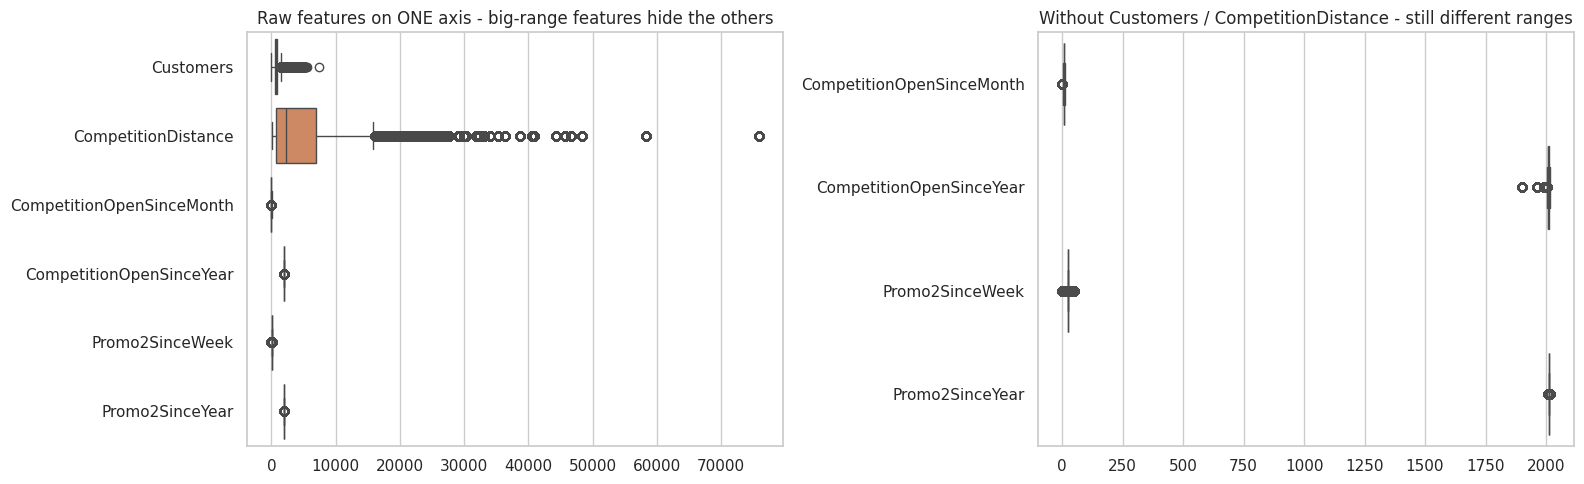

In [ ]:
display(X_train.agg(["min", "max", "mean", "std"]).T.assign(range=lambda t: t["max"] - t["min"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=X_train, orient="h", ax=axes[0])
axes[0].set_title("Raw features on ONE axis - big-range features hide the others")
sns.boxplot(data=X_train.drop(columns=["Customers", "CompetitionDistance"]), orient="h", ax=axes[1])
axes[1].set_title("Without Customers / CompetitionDistance - still different ranges")
plt.tight_layout()
plt.show()

## 5. The scalers
| Scaler | Formula | Result | Uses |
|---|---|---|---|
| `StandardScaler` | `(x - mean) / std` | mean 0, std 1 (unbounded) | mean & std |
| `MinMaxScaler` | `(x - min) / (max - min)` | range [0, 1] | min & max |
| `MaxAbsScaler` | `x / max(abs(x))` | range [-1, 1], keeps zeros (good for sparse data) | max |
| `RobustScaler` | `(x - median) / IQR` | median 0, IQR 1 - **ignores outliers** | median & quartiles |

In [ ]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler(),
}

scaled_train, scaled_test = {}, {}
for name, sc in scalers.items():
    scaled_train[name] = pd.DataFrame(sc.fit_transform(X_train), columns=num_cols, index=X_train.index)  # fit on TRAIN
    scaled_test[name] = pd.DataFrame(sc.transform(X_test), columns=num_cols, index=X_test.index)         # only transform TEST

summary = pd.concat(
    {"Original": X_train.agg(["mean", "std", "min", "max"]).T,
     **{n: d.agg(["mean", "std", "min", "max"]).T for n, d in scaled_train.items()}},
    names=["scaler", "feature"],
)
display(summary)

mean       std       min  \
scaler         feature                                                   
Original       Customers                   763.806   401.871     8.000   
               CompetitionDistance       5,450.758 7,803.070    20.000   
               CompetitionOpenSinceMonth     7.471     2.675     1.000   
               CompetitionOpenSinceYear  2,009.113     4.961 1,900.000   
               Promo2SinceWeek              22.613     9.967     1.000   
               Promo2SinceYear           2,011.877     1.178 2,009.000   
StandardScaler Customers                    -0.000     1.000    -1.881   
               CompetitionDistance          -0.000     1.000    -0.696   
               CompetitionOpenSinceMonth     0.000     1.000    -2.419   
               CompetitionOpenSinceYear      0.000     1.000   -21.994   
               Promo2SinceWeek               0.000     1.000    -2.169   
               Promo2SinceYear              -0.000     1.000    -2.442   
MinMaxScaler   Customers                     0.102     0.054     0.000   
               CompetitionDistance           0.072     0.103     0.000   
               CompetitionOpenSinceMonth     0.588     0.243     0.000   
               CompetitionOpenSinceYear      0.949     0.043     0.000   
               Promo2SinceWeek               0.441     0.203     0.000   
               Promo2SinceYear               0.480     0.196     0.000   
MaxAbsScaler   Customers                     0.103     0.054     0.001   
               CompetitionDistance           0.072     0.103     0.000   
               CompetitionOpenSinceMonth     0.623     0.223     0.083   
               CompetitionOpenSinceYear      0.997     0.002     0.943   
               Promo2SinceWeek               0.452     0.199     0.020   
               Promo2SinceYear               0.998     0.001     0.997   
RobustScaler   Customers                     0.231     1.072    -1.784   
               CompetitionDistance           0.507     1.265    -0.373   
               CompetitionOpenSinceMonth    -0.176     0.892    -2.333   
               CompetitionOpenSinceYear     -0.296     1.654   -36.667   
               Promo2SinceWeek               0.613     9.967   -21.000   
               Promo2SinceYear              -0.123     1.178    -3.000   

                                                max  
scaler         feature                               
Original       Customers                  7,388.000  
               CompetitionDistance       75,860.000  
               CompetitionOpenSinceMonth     12.000  
               CompetitionOpenSinceYear   2,015.000  
               Promo2SinceWeek               50.000  
               Promo2SinceYear            2,015.000  
StandardScaler Customers                     16.483  
               CompetitionDistance            9.023  
               CompetitionOpenSinceMonth      1.693  
               CompetitionOpenSinceYear       1.187  
               Promo2SinceWeek                2.748  
               Promo2SinceYear                2.651  
MinMaxScaler   Customers                      1.000  
               CompetitionDistance            1.000  
               CompetitionOpenSinceMonth      1.000  
               CompetitionOpenSinceYear       1.000  
               Promo2SinceWeek                1.000  
               Promo2SinceYear                1.000  
MaxAbsScaler   Customers                      1.000  
               CompetitionDistance            1.000  
               CompetitionOpenSinceMonth      1.000  
               CompetitionOpenSinceYear       1.000  
               Promo2SinceWeek                1.000  
               Promo2SinceYear                1.000  
RobustScaler   Customers                     17.896  
               CompetitionDistance           11.919  
               CompetitionOpenSinceMonth      1.333  
               CompetitionOpenSinceYear       1.667  
               Promo2SinceWeek               28.000  
   

**Things to notice in the table above**
- `CompetitionOpenSinceYear` contains the bad value **1900** (found in notebook 01). It stretches the range, so
  `MinMaxScaler` squeezes almost every store into 0.94-1.0 (mean 0.949, std 0.043) and `StandardScaler` gives that one row
  a z-score of about -22. Fix the outlier (notebook 04) *before* scaling.
- `RobustScaler` looks odd for `Promo2SinceWeek` (std about 10). Half of its values were filled with the same median, so the IQR
  collapses and the division blows the scale up. With a better imputation (notebook 03) this goes away.

**Manual check** - the sklearn result must equal the formula:

In [ ]:
x = X_train["CompetitionDistance"]
q1, q3 = x.quantile(0.25), x.quantile(0.75)

manual = {
    "StandardScaler": (x - x.mean()) / x.std(ddof=0),        # sklearn uses the population std (ddof=0)
    "MinMaxScaler": (x - x.min()) / (x.max() - x.min()),
    "MaxAbsScaler": x / x.abs().max(),
    "RobustScaler": (x - x.median()) / (q3 - q1),
}
for name, values in manual.items():
    same = np.allclose(values, scaled_train[name]["CompetitionDistance"])
    print(f"{name:15s} manual formula == sklearn ? {same}")

StandardScaler  manual formula == sklearn ? True
MinMaxScaler    manual formula == sklearn ? True
MaxAbsScaler    manual formula == sklearn ? True
RobustScaler    manual formula == sklearn ? True


**What happens on the test set?** The scaler only knows the *training* statistics, so test values are not perfectly
centred, and `MinMaxScaler` can produce values **outside [0, 1]** whenever the test data contains new extremes
(in this particular split it happens to be 0 values, but a future month could break it).
That is normal and expected - it is exactly what would happen on new data in production.

In [ ]:
print("StandardScaler - mean / std on TEST (not exactly 0 / 1):")
display(scaled_test["StandardScaler"].agg(["mean", "std"]).T)

print("MinMaxScaler - how many TEST values fall outside [0, 1]:")
mm_test = scaled_test["MinMaxScaler"]
display(((mm_test < 0) | (mm_test > 1)).sum().to_frame("values outside [0,1]").T)

StandardScaler - mean / std on TEST (not exactly 0 / 1):


,mean,std
Customers,-0.037,0.975
CompetitionDistance,-0.001,0.996
CompetitionOpenSinceMonth,0.001,1.001
CompetitionOpenSinceYear,-0.002,1.036
Promo2SinceWeek,0.018,1.015
Promo2SinceYear,0.003,1.016


MinMaxScaler - how many TEST values fall outside [0, 1]:


,Customers,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2SinceWeek,Promo2SinceYear
"values outside [0,1]",0,0,0,0,0,0


## 6. Visual comparison - scaling changes the *scale*, not the *shape*
The histogram of a feature looks identical after any of these scalers - only the x-axis numbers change.
(Changing the *shape*, e.g. fixing skew, is the job of notebook 06.)

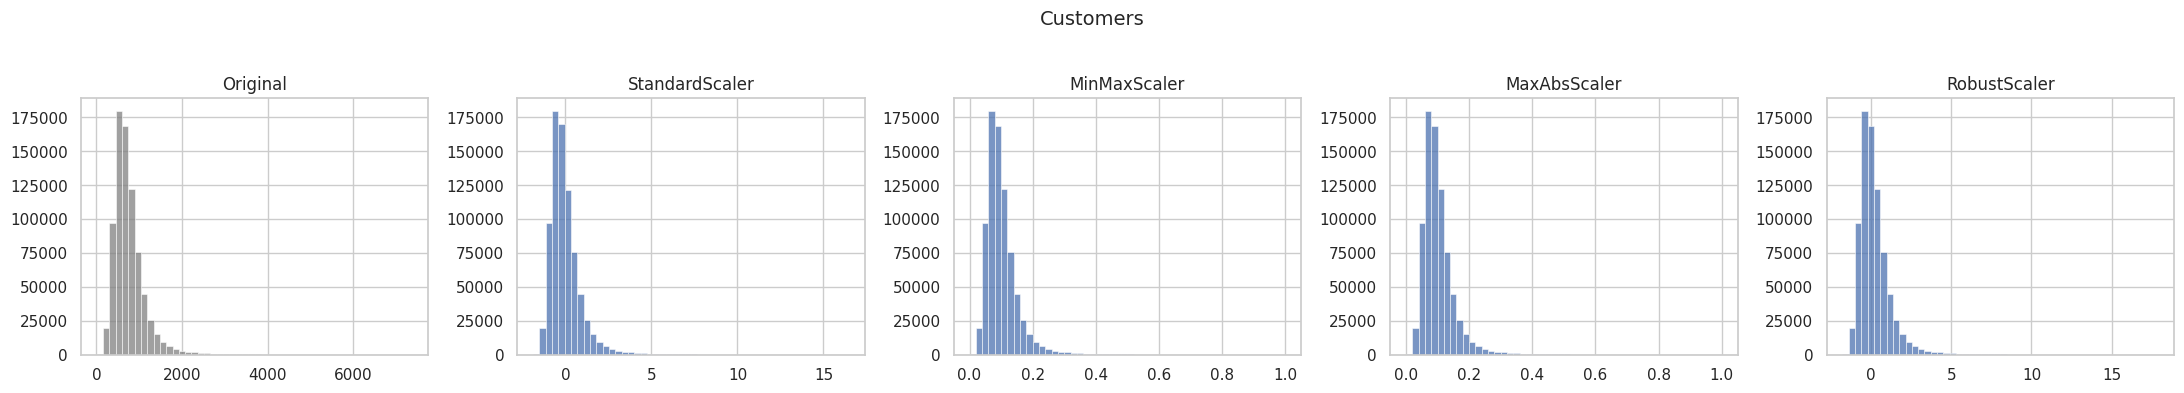

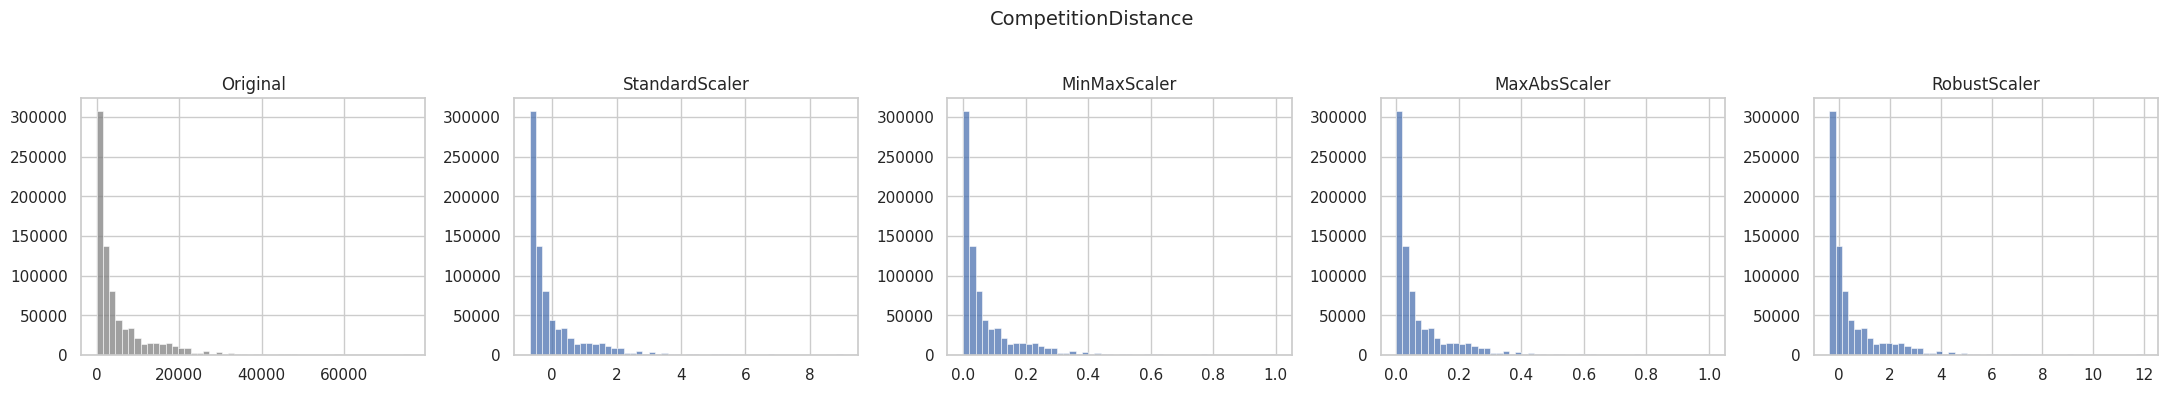

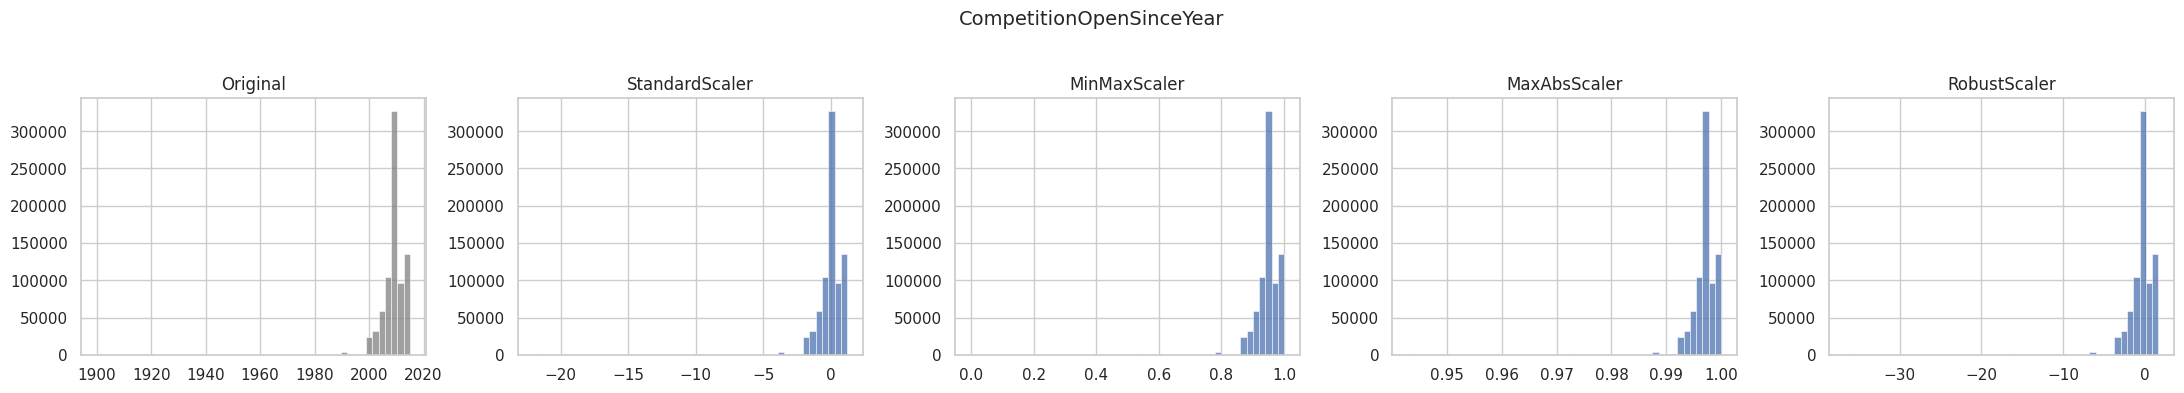

In [ ]:
def compare_distributions(feature):
    fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
    sns.histplot(X_train[feature], bins=50, ax=axes[0], color="gray")
    axes[0].set_title("Original")
    for ax, (name, d) in zip(axes[1:], scaled_train.items()):
        sns.histplot(d[feature], bins=50, ax=ax)
        ax.set_title(name)
    for ax in axes:
        ax.set_xlabel(""); ax.set_ylabel("")
    fig.suptitle(feature, fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()

compare_distributions("Customers")
compare_distributions("CompetitionDistance")
compare_distributions("CompetitionOpenSinceYear")

In [ ]:
# Skewness is identical before and after (scaling is a linear transformation)
skew = pd.DataFrame({"Original": X_train.skew(), **{n: d.skew() for n, d in scaled_train.items()}})
display(skew)

,Original,StandardScaler,MinMaxScaler,MaxAbsScaler,RobustScaler
Customers,2.772,2.772,2.772,2.772,2.772
CompetitionDistance,2.980,2.980,2.980,2.980,2.980
CompetitionOpenSinceMonth,-0.472,-0.472,-0.472,-0.472,-0.472
CompetitionOpenSinceYear,-9.105,-9.105,-9.105,-9.105,-9.105
Promo2SinceWeek,0.338,0.338,0.338,0.338,0.338
Promo2SinceYear,-0.483,-0.483,-0.483,-0.483,-0.483


## 7. Effect of outliers
`CompetitionDistance` has a long right tail. `MinMaxScaler` and `StandardScaler` use the **min/max** and the **mean/std**,
which are pulled by extreme values, while `RobustScaler` uses the **median and IQR**.

MinMax: share of values squeezed below 0.1  -> 76.8%
Standard: largest z-score                  -> 9.0
Robust:  95th percentile / maximum         -> 2.9 / 11.9


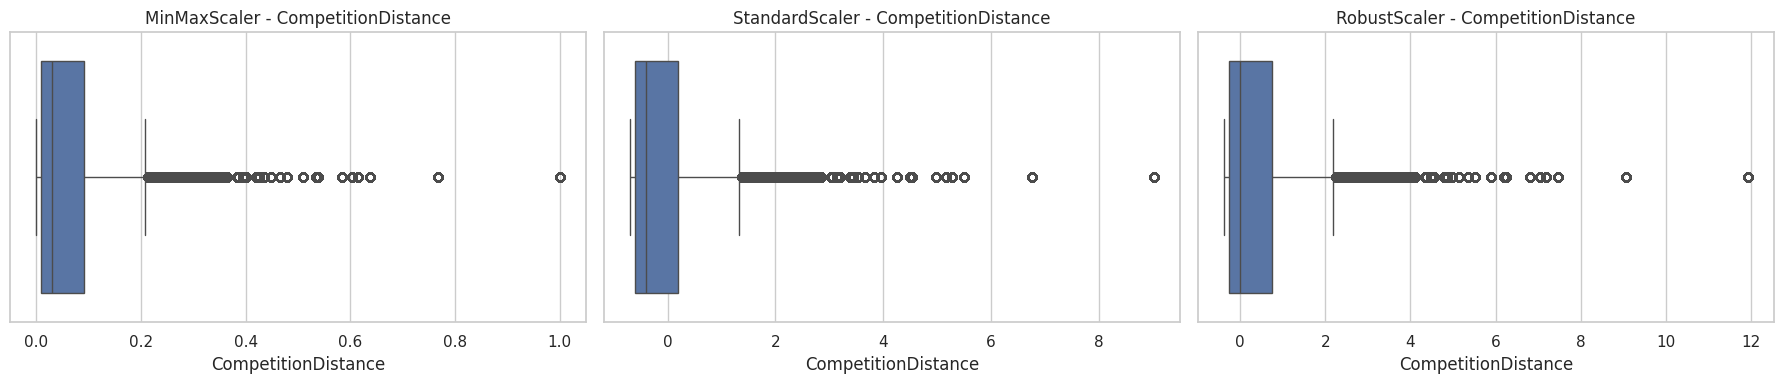

In [ ]:
col = "CompetitionDistance"
mm, ss, rb = scaled_train["MinMaxScaler"][col], scaled_train["StandardScaler"][col], scaled_train["RobustScaler"][col]

print(f"MinMax: share of values squeezed below 0.1  -> {(mm < 0.1).mean():.1%}")
print(f"Standard: largest z-score                  -> {ss.max():.1f}")
print(f"Robust:  95th percentile / maximum         -> {rb.quantile(0.95):.1f} / {rb.max():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (n, s) in zip(axes, [("MinMaxScaler", mm), ("StandardScaler", ss), ("RobustScaler", rb)]):
    sns.boxplot(x=s, ax=ax); ax.set_title(f"{n} - {col}")
plt.tight_layout()
plt.show()

**Reading:** with `MinMaxScaler`, a handful of far-away competitors defines the maximum, so most stores are crushed into a
small part of [0, 1]. `RobustScaler` keeps the bulk of the data on a sensible scale and just lets the outliers stay
large. If you plan to *remove or cap* outliers (notebook 04) do it **before** MinMax / Standard scaling.

## 8. Normalizer (row-wise) - a different idea
All the scalers above work **per column (feature)**. `Normalizer` works **per row (sample)**: it rescales every row so its
vector length (L2 norm) is 1. It is useful for text / cosine-similarity problems, and is **not** the usual choice for
tabular regression like ours - we show it only so you don't confuse it with feature scaling.

In [ ]:
norm = Normalizer(norm="l2")
X_norm = pd.DataFrame(norm.fit_transform(X_train.head(5)), columns=num_cols)
display(X_norm)
print("Row norms:", np.linalg.norm(X_norm.values, axis=1).round(3))

,Customers,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2SinceWeek,Promo2SinceYear
0,0.436,0.494,0.003,0.532,0.006,0.532
1,0.006,0.999,0.000,0.035,0.000,0.034
2,0.016,0.971,0.001,0.167,0.003,0.167
3,0.716,0.051,0.002,0.492,0.005,0.493
4,0.835,0.211,0.001,0.360,0.004,0.360


Row norms: [1. 1. 1. 1. 1.]


## 9. Effect on models
We compare 3 models with **no scaling** vs each scaler. Everything is done inside a `Pipeline`, so the imputer and the scaler
are fitted on the training data only. (We use random samples to keep it fast.)

In [ ]:
train_s = train.sample(60_000, random_state=RANDOM_STATE)
test_s = test.sample(20_000, random_state=RANDOM_STATE)
features = num_cols + binary_cols

def make_pipeline(scaler, model):
    prep = ColumnTransformer(
        [("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", scaler)]), num_cols)],
        remainder="passthrough",          # binary columns go through untouched
    )
    return Pipeline([("prep", prep), ("model", model)])

models = {
    "KNN (k=10)": lambda: KNeighborsRegressor(n_neighbors=10),
    "Ridge": lambda: Ridge(alpha=1.0),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=50, max_depth=12, n_jobs=-1, random_state=RANDOM_STATE),
}
scaler_options = {
    "No scaling": "passthrough",
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

rows = []
for m_name, m_factory in models.items():
    for s_name, scaler in scaler_options.items():
        pipe = make_pipeline(scaler, m_factory())
        pipe.fit(train_s[features], train_s[target])
        pred = pipe.predict(test_s[features])
        rows.append({"model": m_name, "scaler": s_name,
                     "RMSE": np.sqrt(mean_squared_error(test_s[target], pred)),
                     "R2": r2_score(test_s[target], pred)})

results = pd.DataFrame(rows)
display(results.pivot(index="scaler", columns="model", values="RMSE").loc[list(scaler_options)].rename_axis("RMSE (lower is better)"))
display(results.pivot(index="scaler", columns="model", values="R2").loc[list(scaler_options)].rename_axis("R2 (higher is better)"))

model,KNN (k=10),Random Forest,Ridge
RMSE (lower is better),,,
No scaling,"1,280.357","1,108.822","1,687.051"
StandardScaler,"1,149.277","1,108.597","1,687.049"
MinMaxScaler,"1,196.409","1,108.965","1,686.743"
RobustScaler,"1,115.895","1,108.794","1,687.049"


model,KNN (k=10),Random Forest,Ridge
R2 (higher is better),,,
No scaling,0.830,0.873,0.705
StandardScaler,0.863,0.873,0.705
MinMaxScaler,0.852,0.873,0.705
RobustScaler,0.871,0.873,0.705


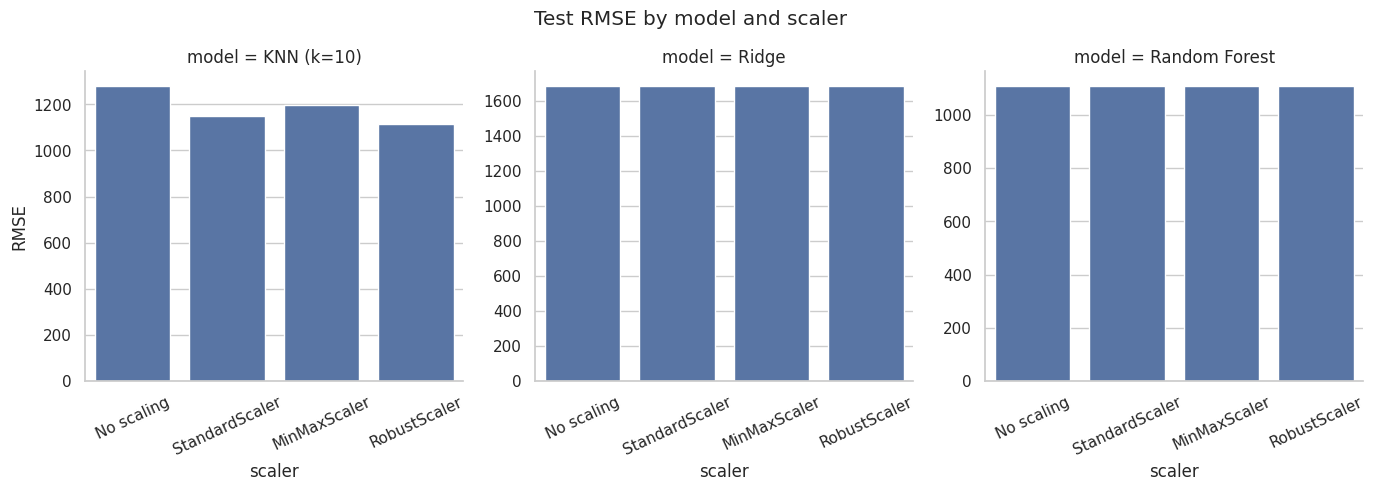

In [ ]:
g = sns.catplot(data=results, x="scaler", y="RMSE", col="model", kind="bar", height=4.2, aspect=1.1, sharey=False)
g.set_xticklabels(rotation=25)
g.fig.suptitle("Test RMSE by model and scaler", y=1.05)
plt.show()

**Reading the results (from our run)**
- **Random Forest** - RMSE is practically the same with or without scaling (about 1,109). Trees split on thresholds, so
  monotonic rescaling changes nothing. **No scaling needed.**
- **KNN** - scaling matters a lot: RMSE drops from about 1,280 (no scaling) to 1,149 (Standard) and 1,116 (Robust);
  MinMax is in between (1,196). Without scaling, `CompetitionDistance` and `Customers` dominate the distance and the small-range
  features are ignored. `RobustScaler` does best here, which fits the outliers we saw (`CompetitionDistance`, the 1900 year).
- **Ridge** - almost no difference. Ridge has a very mild penalty (`alpha=1`) and we have lots of rows, so its predictions
  barely change. Scaling would matter more with stronger regularisation, with Lasso, or with gradient-based solvers.
- Ridge is also the weakest model (R2 about 0.71 vs 0.87): the relationship with `Sales` is not linear in these raw features.

> Takeaway: scaling is **essential for distance-based models (KNN)**, **harmless for linear models**, and **unnecessary for trees**.
> The exact numbers can change slightly if you change the random sample.

## 10. Production-style `ColumnTransformer` + `inverse_transform`
This is the block that goes into the **full pipeline (notebook 08)**: scale only the numeric columns, pass binary columns
through, fit on train, reuse on test / new data.

In [ ]:
final_prep = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_cols),
        ("bin", "passthrough", binary_cols),
    ],
    verbose_feature_names_out=False,
)
final_prep.set_output(transform="pandas")

X_train_final = final_prep.fit_transform(train[features])
X_test_final = final_prep.transform(test[features])

print("Train:", X_train_final.shape, "| Test:", X_test_final.shape)
display(X_train_final.head())
display(X_train_final[num_cols].agg(["mean", "std"]).T)

Train: (785727, 9) | Test: (58611, 9)


,Customers,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2SinceWeek,Promo2SinceYear,Promo,SchoolHoliday,Promo2
68099,2.198,-0.459,0.945,0.380,-0.061,0.104,0,0,0
68136,-1.022,6.768,-1.298,0.784,-0.061,0.104,0,0,0
68223,-1.413,0.798,0.571,0.380,0.842,0.953,0,0,1
68273,5.370,-0.672,0.198,0.179,-0.061,0.104,0,0,0
68276,9.715,-0.547,-0.924,0.784,-0.061,0.104,0,0,0


,mean,std
Customers,-0.000,1.000
CompetitionDistance,-0.000,1.000
CompetitionOpenSinceMonth,0.000,1.000
CompetitionOpenSinceYear,0.000,1.000
Promo2SinceWeek,0.000,1.000
Promo2SinceYear,-0.000,1.000


In [ ]:
# Go back to the original units when needed
scaler_fitted = final_prep.named_transformers_["num"].named_steps["scaler"]
back = pd.DataFrame(scaler_fitted.inverse_transform(X_train_final[num_cols]), columns=num_cols, index=X_train_final.index)

imputed_original = pd.DataFrame(final_prep.named_transformers_["num"].named_steps["imputer"].transform(train[num_cols]),
                                columns=num_cols, index=train.index)
print("inverse_transform recovers the (imputed) original values:", np.allclose(back, imputed_original))

inverse_transform recovers the (imputed) original values: True


In [ ]:
# Save the fitted preprocessor so the same scaling can be re-used later (e.g. in notebook 08 / deployment)
joblib.dump(final_prep, "numeric_scaling_preprocessor.joblib")
print("Saved: numeric_scaling_preprocessor.joblib")

Saved: numeric_scaling_preprocessor.joblib


## 11. Which scaler should I use?
| Situation | Recommended |
|---|---|
| Default for linear models, SVM, KNN, neural nets, PCA | **StandardScaler** |
| Need a fixed range [0, 1] (e.g. neural nets with sigmoid, image-like data) and no big outliers | **MinMaxScaler** |
| Feature has **outliers / long tail** (like `CompetitionDistance`) and you keep them | **RobustScaler** |
| Sparse data with many zeros | **MaxAbsScaler** |
| Tree-based models (Random Forest, XGBoost, LightGBM) | **No scaling needed** |
| Binary flags, categorical codes, the target | **Don't scale** |

**Summary for this project**
- Scale: `Customers`, `CompetitionDistance`, `CompetitionOpenSinceMonth/Year`, `Promo2SinceWeek/Year`.
- Our pick for a distance-based / linear model: **StandardScaler** for most features, **RobustScaler** for `CompetitionDistance` if its outliers are kept.
- Always **fit on train only** and wrap everything in a `Pipeline` / `ColumnTransformer`.
- Scaling does not fix skew - that is notebook 06 (e.g. log-transform `CompetitionDistance` first, then scale).